In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, RobustScaler
from sklearn.metrics import classification_report, confusion_matrix
 
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
 
import warnings
warnings.filterwarnings('ignore')

### Data Collection / Exploration

In [2]:
df = pd.read_csv("diabetes_dataset.csv")
df

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,2018,Female,33.0,Wyoming,0,0,0,0,1,0,0,never,21.21,6.5,90,0
99996,2016,Female,80.0,Wyoming,0,1,0,0,0,0,0,No Info,36.66,5.7,100,0
99997,2018,Male,46.0,Wyoming,0,1,0,0,0,0,0,ever,36.12,6.2,158,0
99998,2018,Female,51.0,Wyoming,1,0,0,0,0,0,0,not current,29.29,6.0,155,0


In [3]:
df.describe()

,year,age,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,2018.360820,41.885856,0.202230,0.200150,0.198760,0.19888,0.199980,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,1.345239,22.516840,0.401665,0.400114,0.399069,0.39916,0.399987,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,2015.000000,0.080000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,2019.000000,24.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,2019.000000,43.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,2019.000000,60.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,2022.000000,80.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [4]:
df.isnull().sum()

year                    0
gender                  0
age                     0
location                0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  object 
 2   age                   100000 non-null  float64
 3   location              100000 non-null  object 
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          100000 non-null  int64  
 10  heart_disease         100000 non-null  int64  
 11  smoking_history       100000 non-null  object 
 12  bmi                   100000 non-null  float64
 13  hbA1c_level           100000 non-null  float64
 14  blood_glucose_level   100000 non-null  int64  
 15  d

In [6]:
df.duplicated().sum()

np.int64(14)

In [7]:
for col in df.select_dtypes('object'):
    print(f'\n', col, df[col].unique())


 gender ['Female' 'Male' 'Other']

 location ['Alabama' 'Alaska' 'Arizona' 'Arkansas' 'California' 'Colorado'
 'Connecticut' 'Delaware' 'District of Columbia' 'Florida' 'Georgia'
 'Guam' 'Hawaii' 'Idaho' 'Illinois' 'Indiana' 'Iowa' 'Kansas' 'Kentucky'
 'Louisiana' 'Maine' 'Maryland' 'Massachusetts' 'Michigan' 'Minnesota'
 'Mississippi' 'Missouri' 'Montana' 'Nebraska' 'Nevada' 'New Hampshire'
 'New Jersey' 'New Mexico' 'New York' 'North Carolina' 'North Dakota'
 'Ohio' 'Oklahoma' 'Oregon' 'Pennsylvania' 'Puerto Rico' 'Rhode Island'
 'South Carolina' 'South Dakota' 'Tennessee' 'Texas' 'United States'
 'Utah' 'Vermont' 'Virgin Islands' 'Virginia' 'Washington' 'West Virginia'
 'Wisconsin' 'Wyoming']

 smoking_history ['never' 'not current' 'current' 'No Info' 'ever' 'former']


#### Phase 1

- Process: Check the dataset's quantitative/ qualitative features and rows. ALso its nature using pandas framework 

- Summary:The dataset is almost clean and curated, only few duplcates are visible


### Data Cleaning

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 99986 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  99986 non-null  int64  
 1   gender                99986 non-null  object 
 2   age                   99986 non-null  float64
 3   location              99986 non-null  object 
 4   race:AfricanAmerican  99986 non-null  int64  
 5   race:Asian            99986 non-null  int64  
 6   race:Caucasian        99986 non-null  int64  
 7   race:Hispanic         99986 non-null  int64  
 8   race:Other            99986 non-null  int64  
 9   hypertension          99986 non-null  int64  
 10  heart_disease         99986 non-null  int64  
 11  smoking_history       99986 non-null  object 
 12  bmi                   99986 non-null  float64
 13  hbA1c_level           99986 non-null  float64
 14  blood_glucose_level   99986 non-null  int64  
 15  diabetes              99

#### 2nd Phase
- Process: Removed the duplicates
- Summary: Data is clean and ready for in-depth outlier detection, feature engineering and data preprocessing

### Train / Test Split

In [10]:
x = df.drop('diabetes', axis=1)
y = df['diabetes']

In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # ← critical for imbalanced targets
)

In [12]:
train_df = x_train.copy()
train_df['diabetes'] = y_train.values

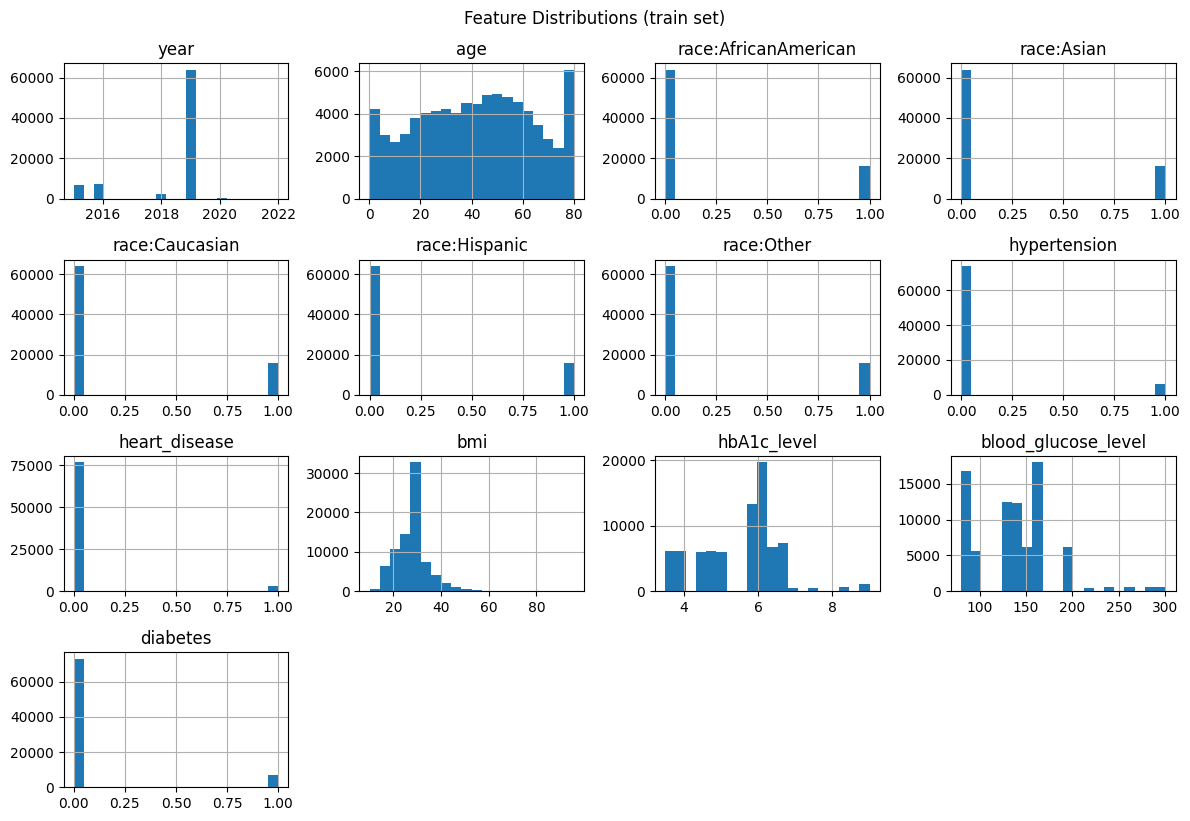

In [13]:
train_df.hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.suptitle("Feature Distributions (train set)", y=1.02)
plt.show()

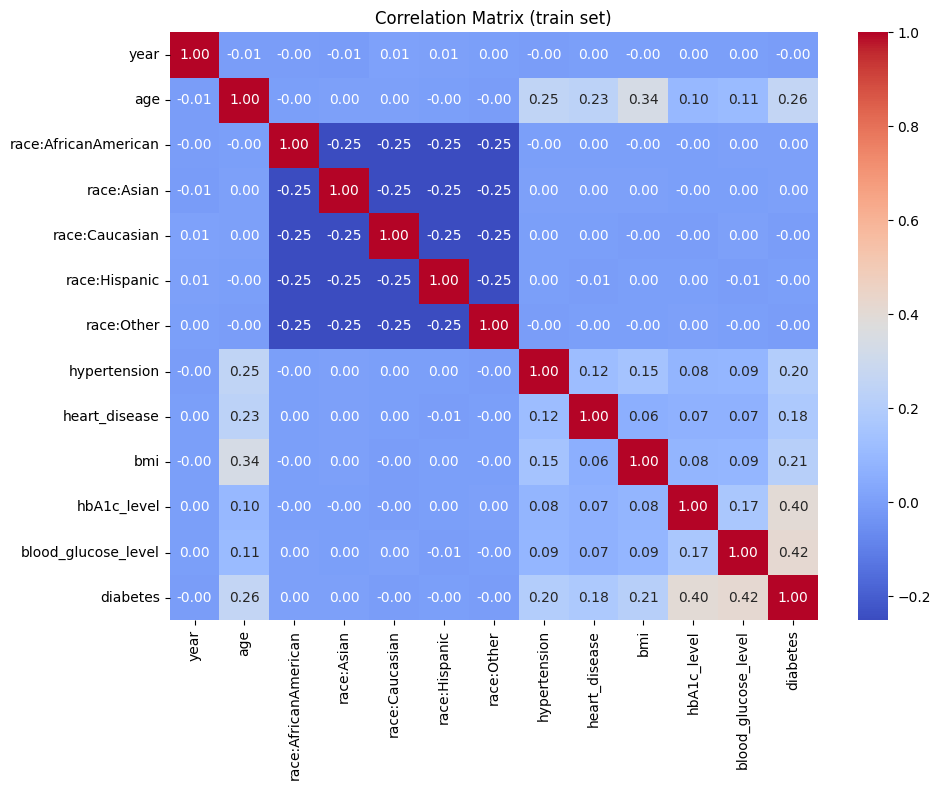

In [14]:
# Correlation heatmap
num_train = train_df.select_dtypes(include=['float64', 'int64'])
plt.figure(figsize=(10, 8))
sns.heatmap(num_train.corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Matrix (train set)")
plt.tight_layout()
plt.show()

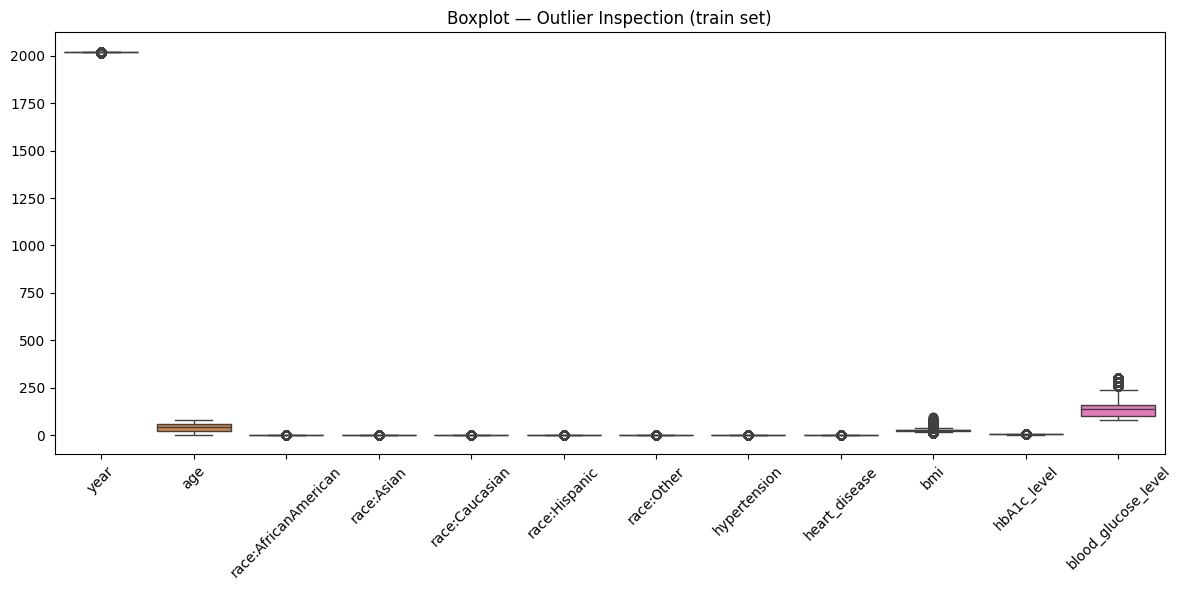

In [15]:
# Boxplot for outlier inspection
plt.figure(figsize=(12, 6))
sns.boxplot(data=x_train.select_dtypes(include=['float64', 'int64']))
plt.title("Boxplot — Outlier Inspection (train set)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Data Preprocessing

In [16]:
cat_cols = x_train.select_dtypes(include='object').columns.tolist()
num_cols = x_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [17]:
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
x_train[cat_cols] = encoder.fit_transform(x_train[cat_cols])
x_test[cat_cols]  = encoder.transform(x_test[cat_cols])

In [18]:
scaler = RobustScaler()
x_train = scaler.fit_transform(x_train)
x_test  = scaler.transform(x_test)

In [19]:
# Class Imbalance Check
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
spw = neg / pos   # scale_pos_weight for XGBoost
print(f"\nClass balance — 0: {neg} | 1: {pos} | scale_pos_weight: {spw:.2f}")


Class balance — 0: 73188 | 1: 6800 | scale_pos_weight: 10.76


#### Data Modeling

In [20]:
lg = LogisticRegression(class_weight='balanced', max_iter=1000)
lg.fit(x_train, y_train)
y_pred_lg = lg.predict(x_test)
print("\nLogistic Regression:\n")
print(classification_report(y_test, y_pred_lg))


Logistic Regression:

              precision    recall  f1-score   support

           0       0.99      0.89      0.93     18298
           1       0.41      0.87      0.56      1700

    accuracy                           0.88     19998
   macro avg       0.70      0.88      0.75     19998
weighted avg       0.94      0.88      0.90     19998



In [21]:
xgb = XGBClassifier(
    scale_pos_weight=spw,   
    eval_metric='logloss',
    random_state=42
)
xgb.fit(x_train, y_train)
y_pred_xgb = xgb.predict(x_test)
print("\nXGBoost:\n")
print(classification_report(y_test, y_pred_xgb))


XGBoost:

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     18298
           1       0.54      0.86      0.67      1700

    accuracy                           0.93     19998
   macro avg       0.77      0.90      0.81     19998
weighted avg       0.95      0.93      0.93     19998

